# Low Rank Orthogonalization


## Setup
Experiment: `low_rank_orthogonalization`. Each trial starts from scratch using `alpha_sweep/models.py`: 6 layers, 6 heads, width 384, tied embeddings, vocabulary 50257, sequence length 1024, and FineWeb10B data. Global batch: 512 sequences; device batch: 8; 100 steps, seeds [0], 1048576 validation tokens every 25 steps and at the end. AdamW learning rate is 0.0036; matrix optimizer learning rate is 0.00036 with EMA momentum 0.95 and linear warmdown. BF16 autocast is used for training. Exact source hashes and launch command are embedded below. Dataset shard checksums, GPU and library versions are not captured in this notebook; consult the original trial logs. CUDA may be nondeterministic.

## Spectral transformation
For momentum $M=U\operatorname{diag}(\sigma)V^\top$, each matrix block is first Frobenius-normalized. Linear interpolation maps active singular values to $(1-\alpha)\sigma_i+\alpha$; values of $\alpha>1$ reverse the ordering of active directions. Clipping bounds active values relative to their median. Selective flattening replaces chosen active singular values with 1; low-rank orthogonalization replaces the retained top directions with 1 and the rest with 0. Values at or below $10^{-7}$ are not selected. The optimizer rescales each output to Frobenius norm $\sqrt{\min(m,n)}$ unless it is zero, so unselected values also change scale.

The low rank orthogonalization experiment completed 6 of 6 trials; 0 diverged. Among configurations completed for every seed, top 25% had the lowest mean final validation loss (5.894352) over 1 seed(s). This is the best tested configuration, not evidence of a global optimum.

Every trial used 100 steps and the same GPT architecture and data loader as the alpha sweep. Update norms were matched per matrix block; validation curves in the notebook are rounded console values, while final rankings use full-precision results. Elapsed time includes setup and validation; optimizer-only overhead was not measured.


In [1]:
import json
import matplotlib.pyplot as plt
data = json.loads('[{"label": "momentum", "seed": 0, "status": "completed", "final": 5.925040245056152, "seconds": 720.7093400229933, "validation": [[0, 10.9807], [25, 6.758], [50, 6.2346], [75, 6.0424], [100, 5.925]], "training": [[1, 10.9761], [2, 9.9595], [3, 8.9556], [4, 8.2424], [5, 7.7884], [6, 8.047], [7, 7.6889], [8, 7.8576], [9, 7.8329], [10, 7.8436], [11, 7.3626], [12, 7.6106], [13, 7.5065], [14, 7.4576], [15, 7.1239], [16, 7.2675], [17, 6.9193], [18, 7.9393], [19, 6.7425], [20, 6.8077], [21, 7.0999], [22, 6.8582], [23, 6.928], [24, 6.8446], [25, 7.0641], [26, 7.046], [27, 6.8492], [28, 6.2457], [29, 6.7431], [30, 6.5725], [31, 6.3774], [32, 6.5818], [33, 6.1381], [34, 6.6424], [35, 6.5185], [36, 6.4218], [37, 6.4734], [38, 6.4833], [39, 6.072], [40, 6.1016], [41, 6.2162], [42, 6.1214], [43, 6.2261], [44, 6.1304], [45, 6.0209], [46, 6.3436], [47, 6.2562], [48, 6.339], [49, 6.0264], [50, 6.1934], [51, 6.2856], [52, 6.1126], [53, 6.2012], [54, 6.0416], [55, 6.3885], [56, 6.1344], [57, 6.2121], [58, 6.1235], [59, 6.1894], [60, 5.6908], [61, 5.9047], [62, 5.8661], [63, 6.0386], [64, 5.9096], [65, 6.2018], [66, 6.3212], [67, 6.2364], [68, 6.4219], [69, 6.1486], [70, 5.8672], [71, 5.907], [72, 5.9579], [73, 6.113], [74, 6.0787], [75, 6.177], [76, 6.5799], [77, 5.7771], [78, 5.9216], [79, 5.7381], [80, 6.0833], [81, 5.9384], [82, 5.9297], [83, 6.2041], [84, 6.1405], [85, 6.1099], [86, 5.8017], [87, 6.0448], [88, 6.8011], [89, 6.0242], [90, 6.2531], [91, 6.1063], [92, 5.8096], [93, 5.7301], [94, 6.0562], [95, 6.1183], [96, 5.7211], [97, 6.1428], [98, 6.0454], [99, 6.1316], [100, 5.9002]]}, {"label": "top 10%", "seed": 0, "status": "completed", "final": 5.9017653465271, "seconds": 720.0973670360399, "validation": [[0, 10.9807], [25, 6.5887], [50, 6.1611], [75, 6.0005], [100, 5.9018]], "training": [[1, 10.9761], [2, 10.0012], [3, 9.0777], [4, 8.3846], [5, 7.9084], [6, 8.0517], [7, 7.5618], [8, 7.6859], [9, 7.7335], [10, 7.8778], [11, 7.2694], [12, 7.3172], [13, 7.1025], [14, 7.2588], [15, 6.9521], [16, 7.0218], [17, 6.5899], [18, 7.6058], [19, 6.5016], [20, 6.6043], [21, 6.8945], [22, 6.6332], [23, 6.755], [24, 6.6653], [25, 6.88], [26, 6.9383], [27, 6.6962], [28, 6.1214], [29, 6.5636], [30, 6.4119], [31, 6.2241], [32, 6.4656], [33, 6.0219], [34, 6.5312], [35, 6.3955], [36, 6.3116], [37, 6.3728], [38, 6.3806], [39, 5.9505], [40, 5.9937], [41, 6.1399], [42, 6.0303], [43, 6.1401], [44, 6.0546], [45, 5.9343], [46, 6.2561], [47, 6.1727], [48, 6.1521], [49, 5.9455], [50, 6.1054], [51, 6.2186], [52, 6.0333], [53, 6.1342], [54, 5.9783], [55, 6.3248], [56, 6.0792], [57, 6.1539], [58, 6.0765], [59, 6.125], [60, 5.6501], [61, 5.8611], [62, 5.8126], [63, 5.9948], [64, 5.8659], [65, 6.1407], [66, 6.2695], [67, 6.1847], [68, 6.3716], [69, 6.1013], [70, 5.8162], [71, 5.8619], [72, 5.9144], [73, 6.0685], [74, 6.0324], [75, 6.141], [76, 6.5492], [77, 5.7399], [78, 5.8919], [79, 5.7012], [80, 6.0425], [81, 5.9013], [82, 5.909], [83, 6.1742], [84, 6.1005], [85, 6.0834], [86, 5.7762], [87, 6.0232], [88, 6.7771], [89, 5.9979], [90, 6.2139], [91, 6.0818], [92, 5.7917], [93, 5.7024], [94, 6.0294], [95, 6.0979], [96, 5.7033], [97, 6.1134], [98, 6.0146], [99, 6.113], [100, 5.8749]]}, {"label": "top 25%", "seed": 0, "status": "completed", "final": 5.894351959228516, "seconds": 721.001765316003, "validation": [[0, 10.9807], [25, 6.5893], [50, 6.1556], [75, 5.9926], [100, 5.8944]], "training": [[1, 10.9762], [2, 10.008], [3, 9.0933], [4, 8.4044], [5, 7.9291], [6, 8.0627], [7, 7.5649], [8, 7.6787], [9, 7.7307], [10, 7.9038], [11, 7.3154], [12, 7.3528], [13, 7.1035], [14, 7.2524], [15, 6.9693], [16, 7.0508], [17, 6.6137], [18, 7.6291], [19, 6.5157], [20, 6.6161], [21, 6.9084], [22, 6.6413], [23, 6.7641], [24, 6.6743], [25, 6.8909], [26, 6.9379], [27, 6.6983], [28, 6.1247], [29, 6.573], [30, 6.4285], [31, 6.2254], [32, 6.4599], [33, 6.0225], [34, 6.5258], [35, 6.3968], [36, 6.3062], [37, 6.3704], [38, 6.3752], [39, 5.9421], [40, 5.9887], [41, 6.1371], [42, 6.0288], [43, 6.1369], [44, 6.0524], [45, 5.9285], [46, 6.2542], [47, 6.1693], [48, 6.1316], [49, 5.9404], [50, 6.0983], [51, 6.2073], [52, 6.0334], [53, 6.1292], [54, 5.9707], [55, 6.312], [56, 6.0734], [57, 6.1497], [58, 6.0698], [59, 6.122], [60, 5.6376], [61, 5.856], [62, 5.8061], [63, 5.9826], [64, 5.8609], [65, 6.1337], [66, 6.2621], [67, 6.1759], [68, 6.3639], [69, 6.0922], [70, 5.8054], [71, 5.8514], [72, 5.9044], [73, 6.0576], [74, 6.0314], [75, 6.1357], [76, 6.5442], [77, 5.7331], [78, 5.8829], [79, 5.692], [80, 6.0365], [81, 5.8878], [82, 5.9008], [83, 6.1645], [84, 6.0923], [85, 6.0729], [86, 5.7652], [87, 6.0189], [88, 6.7705], [89, 5.9897], [90, 6.2042], [91, 6.0793], [92, 5.7864], [93, 5.6952], [94, 6.0185], [95, 6.0919], [96, 5.6952], [97, 6.1075], [98, 6.0082], [99, 6.1053], [100, 5.8679]]}, {"label": "top 50%", "seed": 0, "status": "completed", "final": 5.897649765014648, "seconds": 720.9656002930133, "validation": [[0, 10.9807], [25, 6.5964], [50, 6.1584], [75, 5.9957], [100, 5.8976]], "training": [[1, 10.9762], [2, 10.012], [3, 9.1023], [4, 8.4163], [5, 7.9416], [6, 8.0695], [7, 7.5681], [8, 7.6746], [9, 7.7271], [10, 7.9137], [11, 7.3385], [12, 7.3759], [13, 7.1126], [14, 7.255], [15, 6.9817], [16, 7.0662], [17, 6.6285], [18, 7.6449], [19, 6.5292], [20, 6.6271], [21, 6.9206], [22, 6.6506], [23, 6.7744], [24, 6.6861], [25, 6.9025], [26, 6.9427], [27, 6.7042], [28, 6.13], [29, 6.5828], [30, 6.4416], [31, 6.2324], [32, 6.4646], [33, 6.0276], [34, 6.5287], [35, 6.4004], [36, 6.3088], [37, 6.3746], [38, 6.3785], [39, 5.9449], [40, 5.9926], [41, 6.1398], [42, 6.0329], [43, 6.1437], [44, 6.0563], [45, 5.933], [46, 6.2581], [47, 6.1741], [48, 6.1337], [49, 5.947], [50, 6.1002], [51, 6.2075], [52, 6.0355], [53, 6.1305], [54, 5.9736], [55, 6.3141], [56, 6.0775], [57, 6.1501], [58, 6.0708], [59, 6.1265], [60, 5.6399], [61, 5.8583], [62, 5.8047], [63, 5.9849], [64, 5.8653], [65, 6.1379], [66, 6.2623], [67, 6.1762], [68, 6.3663], [69, 6.0946], [70, 5.8079], [71, 5.8572], [72, 5.9106], [73, 6.0577], [74, 6.038], [75, 6.1368], [76, 6.5449], [77, 5.7343], [78, 5.8836], [79, 5.6942], [80, 6.0384], [81, 5.8898], [82, 5.9029], [83, 6.1674], [84, 6.0958], [85, 6.0755], [86, 5.7689], [87, 6.0234], [88, 6.7732], [89, 5.991], [90, 6.2088], [91, 6.0825], [92, 5.7927], [93, 5.6949], [94, 6.0224], [95, 6.0934], [96, 5.698], [97, 6.1146], [98, 6.0117], [99, 6.1074], [100, 5.872]]}, {"label": "top 75%", "seed": 0, "status": "completed", "final": 5.902502536773682, "seconds": 721.6059015360661, "validation": [[0, 10.9807], [25, 6.6004], [50, 6.1617], [75, 5.9998], [100, 5.9025]], "training": [[1, 10.9762], [2, 10.0139], [3, 9.107], [4, 8.4223], [5, 7.9479], [6, 8.0735], [7, 7.57], [8, 7.6733], [9, 7.7249], [10, 7.9162], [11, 7.349], [12, 7.3862], [13, 7.1179], [14, 7.2564], [15, 6.9869], [16, 7.0732], [17, 6.636], [18, 7.6526], [19, 6.5364], [20, 6.6324], [21, 6.9259], [22, 6.6557], [23, 6.7799], [24, 6.6924], [25, 6.9083], [26, 6.9451], [27, 6.7076], [28, 6.134], [29, 6.5884], [30, 6.448], [31, 6.2366], [32, 6.4679], [33, 6.031], [34, 6.5311], [35, 6.4031], [36, 6.3117], [37, 6.3776], [38, 6.3816], [39, 5.9477], [40, 5.9963], [41, 6.1423], [42, 6.0357], [43, 6.1483], [44, 6.0596], [45, 5.9367], [46, 6.2614], [47, 6.178], [48, 6.1391], [49, 5.9519], [50, 6.1026], [51, 6.2099], [52, 6.039], [53, 6.1326], [54, 5.9763], [55, 6.3169], [56, 6.0825], [57, 6.1522], [58, 6.0726], [59, 6.1301], [60, 5.6444], [61, 5.861], [62, 5.8068], [63, 5.9876], [64, 5.8689], [65, 6.1437], [66, 6.2652], [67, 6.1787], [68, 6.3698], [69, 6.0977], [70, 5.8122], [71, 5.8626], [72, 5.9169], [73, 6.0606], [74, 6.043], [75, 6.1403], [76, 6.547], [77, 5.7385], [78, 5.8868], [79, 5.6978], [80, 6.0423], [81, 5.8945], [82, 5.9062], [83, 6.172], [84, 6.1011], [85, 6.079], [86, 5.7743], [87, 6.0273], [88, 6.7747], [89, 5.9941], [90, 6.2133], [91, 6.0866], [92, 5.7979], [93, 5.6991], [94, 6.0289], [95, 6.0961], [96, 5.7024], [97, 6.1216], [98, 6.0177], [99, 6.1121], [100, 5.8772]]}, {"label": "top 100%", "seed": 0, "status": "completed", "final": 5.906902313232422, "seconds": 721.2941335350042, "validation": [[0, 10.9807], [25, 6.6039], [50, 6.1647], [75, 6.0035], [100, 5.9069]], "training": [[1, 10.9762], [2, 10.0152], [3, 9.1097], [4, 8.426], [5, 7.9518], [6, 8.0757], [7, 7.571], [8, 7.6721], [9, 7.7239], [10, 7.9183], [11, 7.3561], [12, 7.3939], [13, 7.122], [14, 7.2588], [15, 6.991], [16, 7.0779], [17, 6.6408], [18, 7.6585], [19, 6.5419], [20, 6.637], [21, 6.9306], [22, 6.6597], [23, 6.7846], [24, 6.6973], [25, 6.9129], [26, 6.9477], [27, 6.7108], [28, 6.1376], [29, 6.5927], [30, 6.4523], [31, 6.2396], [32, 6.471], [33, 6.0339], [34, 6.5336], [35, 6.4048], [36, 6.3145], [37, 6.3805], [38, 6.3848], [39, 5.9506], [40, 5.9999], [41, 6.1446], [42, 6.038], [43, 6.1518], [44, 6.0623], [45, 5.9398], [46, 6.2648], [47, 6.1817], [48, 6.1455], [49, 5.9555], [50, 6.1047], [51, 6.2125], [52, 6.0414], [53, 6.1349], [54, 5.9791], [55, 6.3197], [56, 6.0865], [57, 6.1541], [58, 6.075], [59, 6.1331], [60, 5.6475], [61, 5.8639], [62, 5.8094], [63, 5.9901], [64, 5.8717], [65, 6.1481], [66, 6.2682], [67, 6.1816], [68, 6.3726], [69, 6.1], [70, 5.8159], [71, 5.8667], [72, 5.922], [73, 6.0635], [74, 6.0474], [75, 6.1438], [76, 6.5493], [77, 5.7427], [78, 5.8896], [79, 5.701], [80, 6.0461], [81, 5.8987], [82, 5.9091], [83, 6.1761], [84, 6.1055], [85, 6.0821], [86, 5.7787], [87, 6.0307], [88, 6.776], [89, 5.9977], [90, 6.2176], [91, 6.0905], [92, 5.8017], [93, 5.7032], [94, 6.0339], [95, 6.0989], [96, 5.707], [97, 6.1272], [98, 6.0219], [99, 6.1163], [100, 5.8815]]}]')
config = json.loads('{"steps": 100, "seeds": [0], "device_batch_size": 8, "val_tokens": 1048576, "val_loss_every": 25, "warmdown_iters": 10, "configurations": [{"label": "momentum", "transform": {"kind": "momentum"}}, {"label": "top 10%", "transform": {"kind": "low_rank", "fraction": 0.1}}, {"label": "top 25%", "transform": {"kind": "low_rank", "fraction": 0.25}}, {"label": "top 50%", "transform": {"kind": "low_rank", "fraction": 0.5}}, {"label": "top 75%", "transform": {"kind": "low_rank", "fraction": 0.75}}, {"label": "top 100%", "transform": {"kind": "low_rank", "fraction": 1.0}}], "source_sha256": {"alpha_sweep/train_gpt2_cond_muon.py": "958b28f78c2088ac115beec343a9432478cf8f76642ba435a003ba64bad7686e", "alpha_sweep/models.py": "e2faa7fe98c2591e3da12451eb7cf0c365f5e3b27f4b054eae0d7498515d3523", "metrics.py": "4316184dc68eaba40c2ce6055ad8d965b8753be47f9b3a3c5c4acb7672ea1846", "alpha_sweep/finish_sweep.py": "6ea2553aab3b68d2fe03199ad0e29b11d904ab75584930f335d3b2982ffdec6e", "spectral_experiments/transforms.py": "a0ddd5f5f8a52d871420c855ad785d6b955ad01f86a39293503cf508c446ff2a", "spectral_experiments/run.py": "d1ba7ba64a5420bf6324c9d3e15d96442dfe00786dcd06c46765f4d5757e173e", "spectral_experiments/analysis.py": "3e4a5b5b00d5ed3900cc1fefdb2cd521e0b57c9ac7e1a45c925306c3877fbed4", "low_rank_orthogonalization/launch.sh": "2890ac89a640163690438eaf313e7482f5c5dee976bf7c44c3c74c3d80648233"}, "launch_command": "/workspace/spectral-full-repo-b7137575/spectral_experiments/run.py --experiment low_rank_orthogonalization --output-dir /workspace/spectral-full-b7137575-attempt1/low_rank_orthogonalization --steps 100 --seeds 0 --device-batch-size 8 --val-tokens 1048576 --val-loss-every 25 --publish --repo jhshi1879/condition-number-adaptive-muon --branch main --ssh-key /dev/shm/alpha-publisher/id_ed25519 --known-hosts /dev/shm/alpha-publisher/known_hosts --results-path spectral_experiments/results/full-b7137575/low_rank_orthogonalization"}')
completed = [row for row in data if row['status'] == 'completed']


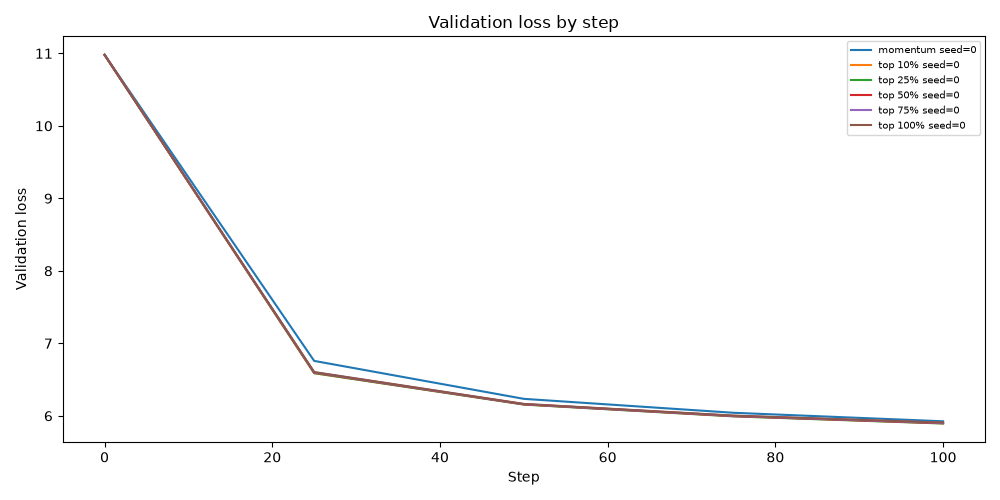

In [2]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.plot(*zip(*row['validation']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Validation loss'); plt.legend(fontsize='x-small')
plt.title('Validation loss by step')
plt.tight_layout()


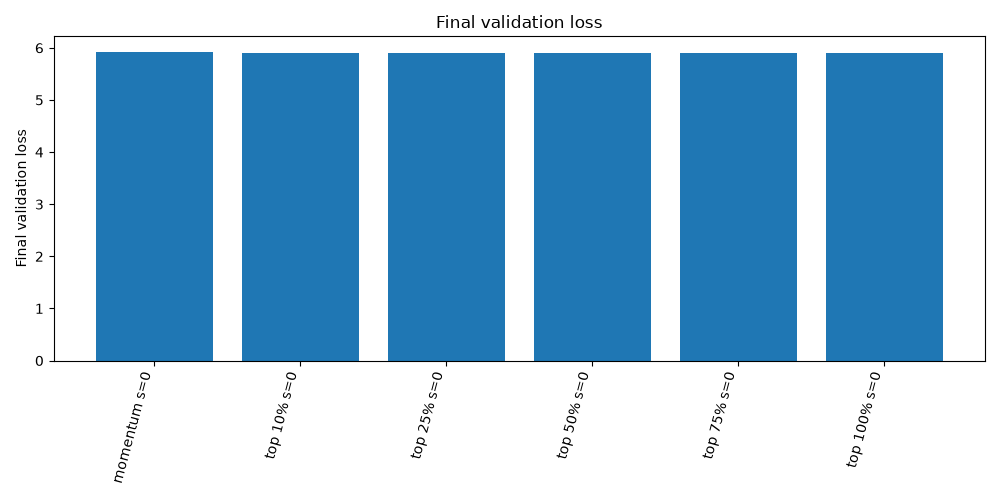

In [3]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(completed)), [row['final'] for row in completed])
plt.xticks(range(len(completed)), [f"{r['label']} s={r['seed']}" for r in completed], rotation=75, ha='right'); plt.ylabel('Final validation loss')
plt.title('Final validation loss')
plt.tight_layout()


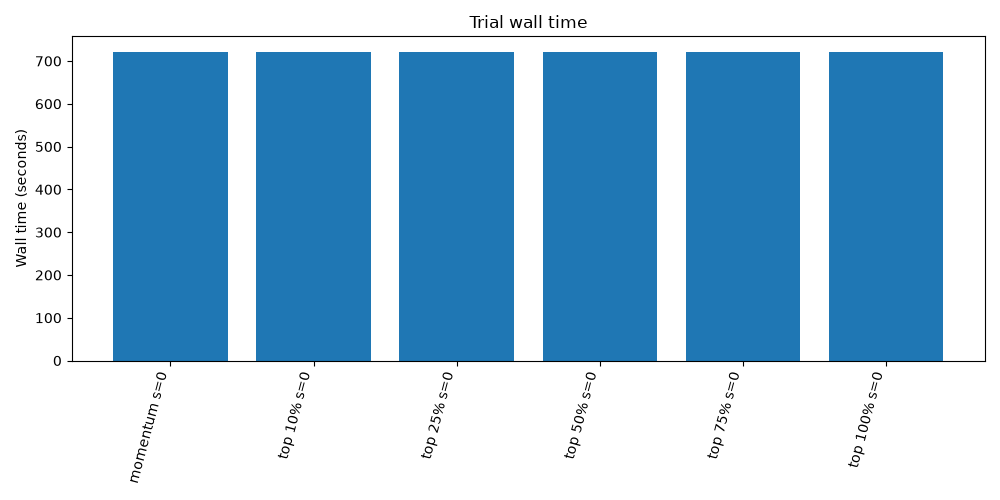

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(data)), [row['seconds'] for row in data])
plt.xticks(range(len(data)), [f"{r['label']} s={r['seed']}" for r in data], rotation=75, ha='right'); plt.ylabel('Wall time (seconds)')
plt.title('Trial wall time')
plt.tight_layout()


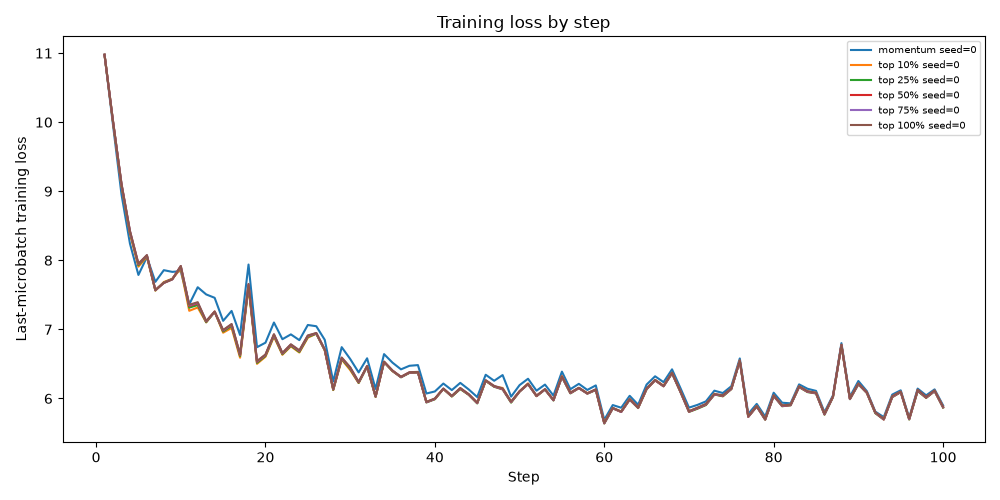

In [5]:
plt.figure(figsize=(10, 5))
for row in completed:
    if row['training']:
        plt.plot(*zip(*row['training']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Last-microbatch training loss'); plt.legend(fontsize='x-small')
plt.title('Training loss by step')
plt.tight_layout()


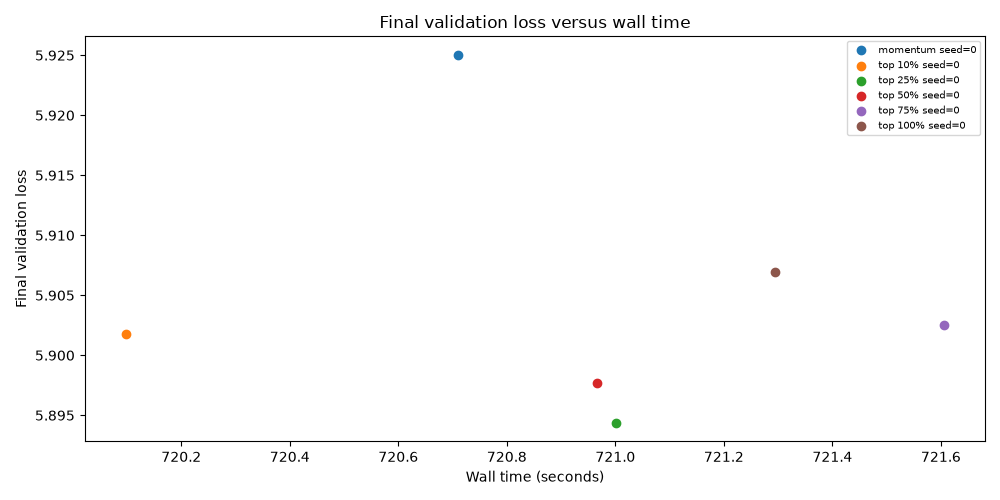

In [6]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.scatter(row['seconds'], row['final'], label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Wall time (seconds)'); plt.ylabel('Final validation loss'); plt.legend(fontsize='x-small')
plt.title('Final validation loss versus wall time')
plt.tight_layout()
